# 04 · Preprocesamiento: DICOM → PNG 224x224

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

Se hace **una sola vez** y se guarda en Drive (`procesadas_224/`), porque leer DICOM de Drive en
cada época es muy lento. Pasos por recorte (función `preprocesar` de `src/modelo_utils.py`):

1. Lectura del DICOM sin `force=True`; si la fotometría es `MONOCHROME1`, se invierte.
2. Normalización **min-max por imagen** a [0, 1].
3. **Relleno a cuadrado** con ceros (`AJUSTE="pad"`), para no deformar la forma de la masa,
   o estirado directo (`AJUSTE="resize"`).
4. Redimensionado a 224x224 con `INTER_AREA`.
5. Se guarda en **8 bits**: se pierde precisión frente a los 12-16 bits originales (documentarlo).

La normalización con media y desviación de ImageNet y los aumentos se aplican después,
al cargar, y los aumentos **solo en entrenamiento**.

In [1]:
!pip install -q pydicom

In [2]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [3]:
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
import modelo_utils as mu

AJUSTE = "pad"      # "pad" (relleno a cuadrado) o "resize" (estirar)
TAM    = 224
FORZAR = False      # True para regenerar todos los PNG (por ejemplo si cambias AJUSTE)

os.makedirs(PNG, exist_ok=True)
disp = pd.read_csv(f"{RES}/lesiones_disponibles.csv")
print("Lesiones a procesar:", len(disp))

Lesiones a procesar: 211


In [4]:
errores = []
for r in tqdm(disp.itertuples(), total=len(disp)):
    out = f"{PNG}/{r.lesion_id}.png"
    if os.path.exists(out) and not FORZAR:
        continue
    try:
        cv2.imwrite(out, mu.preprocesar(r.crop_path, AJUSTE, TAM))
    except Exception as e:
        errores.append((r.lesion_id, str(e)))
        print("ERROR", r.lesion_id, e)

with open(f"{PNG}/config_preprocesamiento.txt", "w") as f:
    f.write(f"ajuste={AJUSTE}\ntam={TAM}\nnormalizacion=min-max por imagen\nbits=8\n")
print("Errores:", len(errores))

  0%|          | 0/211 [00:00<?, ?it/s]

Errores: 0


In [5]:
# Verificación: un PNG por lesión, todos 224x224 y en escala de grises
pngs = {f[:-4] for f in os.listdir(PNG) if f.endswith(".png")}
faltan = set(disp.lesion_id) - pngs
print("PNG:", len(pngs), "| faltan:", len(faltan))
formas = {cv2.imread(f"{PNG}/{l}.png", cv2.IMREAD_UNCHANGED).shape for l in disp.lesion_id}
print("Formas encontradas:", formas)
assert not faltan and formas == {(TAM, TAM)}

PNG: 211 | faltan: 0
Formas encontradas: {(224, 224)}


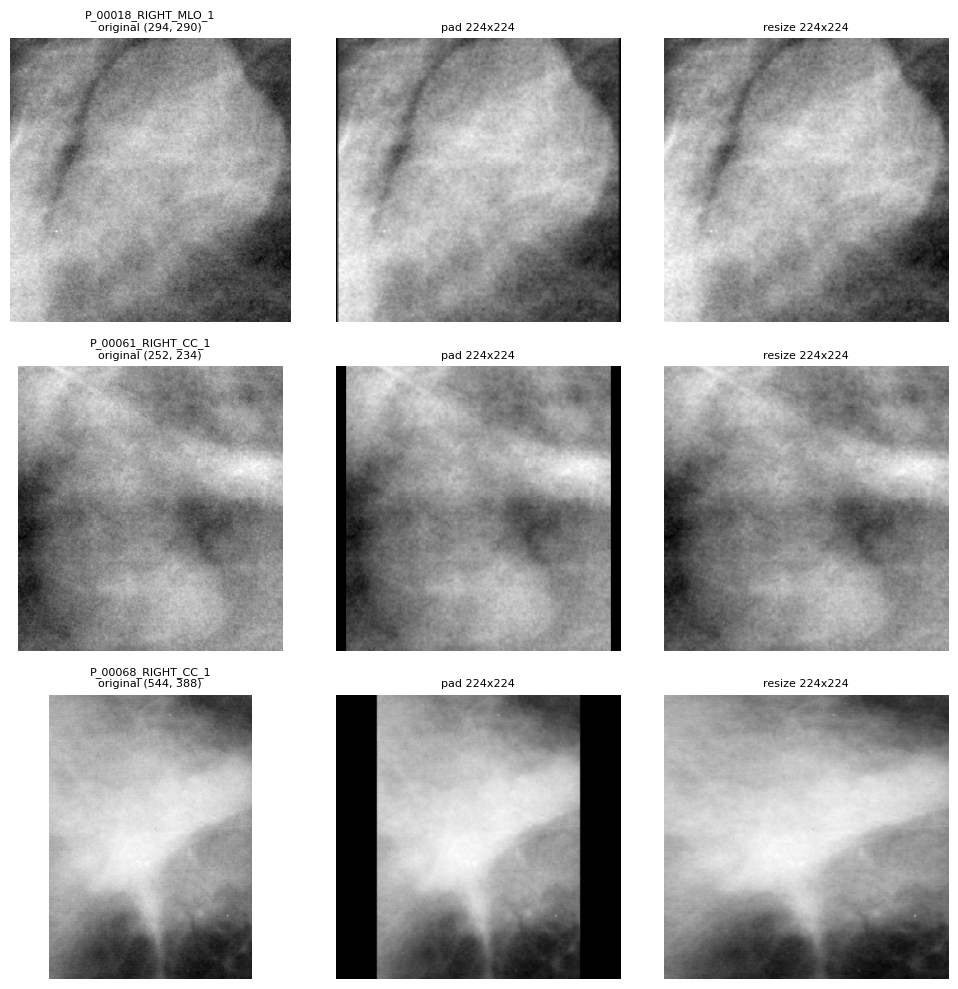

In [6]:
# Antes / después para 3 lesiones de entrenamiento: original, relleno y estirado
train = pd.read_csv(f"{PART}/train.csv")
ej = disp[disp.lesion_id.isin(train.lesion_id)].sample(3, random_state=0)
fig, ax = plt.subplots(3, 3, figsize=(10, 10))
for fila, r in zip(ax, ej.itertuples()):
    orig = mu.leer_recorte(r.crop_path)
    fila[0].imshow(orig, cmap="gray");                                   fila[0].set_title(f"{r.lesion_id}\noriginal {orig.shape}", fontsize=8)
    fila[1].imshow(mu.preprocesar(r.crop_path, "pad"), cmap="gray");    fila[1].set_title("pad 224x224", fontsize=8)
    fila[2].imshow(mu.preprocesar(r.crop_path, "resize"), cmap="gray"); fila[2].set_title("resize 224x224", fontsize=8)
    for a in fila: a.axis("off")
plt.tight_layout()
plt.savefig(f"{RES}/preprocesamiento_ejemplos.png", dpi=110, bbox_inches="tight")
plt.show()